# Demonstrações: busca vetorial de filmes com Oracle

Material de apoio da apresentação do Grupo 3 (MBA em Engenharia de Dados, PUC Minas). Cada seção diz em que parte do roteiro entra e o que mostrar.

**Como usar**

- Roda no computador de quem apresenta, com um Oracle com a base de 400 filmes carregada (o do compose atende em `localhost:1522/FREEPDB1`: defina `DB_DSN` com esse endereço) e o Ollama com o `bge-m3` em `localhost:11434`. No compose, o Ollama não publica porta; por isso o notebook usa o Ollama instalado na máquina.
- No `.venv` do projeto: `pip install -r app/requirements.txt -r requirements-notebook.txt` e escolha o kernel do `.venv` no VS Code.
- Execute tudo (**Run All**) e **salve com as saídas**. Na apresentação, o notebook é aberto já executado, no VS Code ou no GitHub; a demonstração ao vivo continua sendo a página e o `sql/02-search.sql`.
- A senha do `app_embedding` é pedida na primeira célula e não fica gravada no arquivo.

In [3]:
import array
import getpass
import os

import matplotlib.pyplot as plt
import numpy as np
import oracledb
import requests

from app.busca import buscar_filmes
from app.carga import ler_json
from app.database import conectar
from app.embeddings import DIMENSAO, MODELO, URL, gerar_embedding

# A senha é pedida na hora, para não ficar gravada no notebook.
if "DB_PASSWORD" not in os.environ:
    os.environ["DB_PASSWORD"] = getpass.getpass("Senha do app_embedding: ")

# CLOB chega como str, e não como objeto LOB.
oracledb.defaults.fetch_lobs = False

# Uma conexão para o notebook inteiro; é fechada na última célula.
conexao = conectar()


def consultar(sql: str, **binds) -> list[tuple]:
    """Executa um SELECT na conexão aberta e devolve todas as linhas."""
    with conexao.cursor() as cur:
        cur.execute(sql, **binds)
        return cur.fetchall()


def fmt(valor: float, casas: int = 4) -> str:
    """Formata com casas fixas, sem exibir -0.0000 para resíduos de arredondamento."""
    return f"{round(valor, casas) + 0.0:.{casas}f}"


print(f"Oracle {conexao.version} | modelo {MODELO} | {DIMENSAO} dimensões | Ollama em {URL}")

Oracle 23.26.3.0.0 | modelo bge-m3 | 1024 dimensões | Ollama em http://localhost:11434/api/embed


## 1. Um filme por dentro

**Roteiro:** Partes 2 e 3.

O texto que foi para o Ollama e o vetor que voltou, lidos direto da tabela.

- O filme virou 1024 números. Nenhum número sozinho significa algo: o significado está na posição do vetor em relação aos outros.
- `VECTOR_DIMENSION_COUNT` confirma a dimensão da coluna `VECTOR(1024, FLOAT32)`.
- `VECTOR_NORM` igual a 1 mostra que o bge-m3 devolve vetores normalizados.
- Em Python, o vetor chega como `array('f')`, o mesmo tipo usado no bind da carga.

Título: WALL·E
Título original: WALL·E
Ano: 2008
Sinopse: Séculos depois de a humanidade abandonar uma Terra soterrada de lixo, um pequeno robô continua compactando entulho sozinho, guardando objetos curiosos e assistindo a um velho musical. Sua rotina muda com a chegada de EVA, uma robô enviada para procurar sinais de vida no planeta. Ao segui-la, ele vai parar numa nave de luxo onde os humanos vivem sedentários, dependentes das máquinas e sem lembrar como é a Terra. A primeira parte do filme quase não tem diálogos.
Gênero: animação, ficção científica, romance
Direção: Andrew Stanton
Elenco: Ben Burtt, Elissa Knight, Jeff Garlin, Fred Willard, John Ratzenberger, Kathy Najimy, Sigourney Weaver
Clima: para ver em família, romântico, poético, poucos diálogos
Recepção: Aclamado pela crítica e sucesso de bilheteria.

Em Python, o vetor chega como array('f') com 1024 números.
VECTOR_DIMENSION_COUNT = 1024 | VECTOR_NORM = 1.000000
Os 8 primeiros: -0.0212, 0.0184, -0.0022, 0.0324, -0.0032, -0

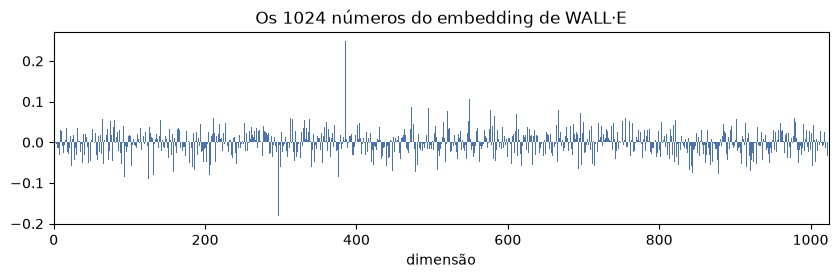

In [4]:
# A desestruturação [(...)] = ... exige exatamente uma linha:
# se o título não existir (ou repetir), dá erro aqui, e não mais adiante.
[(titulo, texto, vetor, dimensao, norma)] = consultar(
    """
    SELECT titulo, texto, embedding,
           VECTOR_DIMENSION_COUNT(embedding),
           VECTOR_NORM(embedding)
    FROM   kb_docs
    WHERE  titulo = :titulo
    """,
    titulo="WALL·E",
)

print(texto)
print()
print(f"Em Python, o vetor chega como array('{vetor.typecode}') com {len(vetor)} números.")
print(f"VECTOR_DIMENSION_COUNT = {dimensao} | VECTOR_NORM = {norma:.6f}")
print("Os 8 primeiros:", ", ".join(fmt(x) for x in vetor[:8]))

fig, ax = plt.subplots(figsize=(10, 2.5))
ax.bar(range(len(vetor)), vetor, width=1.0, color="#4c72b0")
ax.set_title(f"Os {len(vetor)} números do embedding de {titulo}")
ax.set_xlabel("dimensão")
ax.set_xlim(0, len(vetor))
plt.show()

## 2. Frases parecidas ficam perto

**Roteiro:** Parte 2.

Cinco frases vetorizadas pelo bge-m3, com a distância cosseno entre cada par.

- **Mesmo sentido, outras palavras:** "robô" e "máquina" devem ficar perto, mesmo quase sem palavras em comum. É o que o LIKE não faz.
- **Outro idioma:** a frase em inglês também deve ficar perto, porque o bge-m3 é multilíngue.
- **Outro assunto:** "família pobre" e "imposto de renda" devem ficar longe das três primeiras.

Comente o padrão, não decore os números: eles aparecem ao executar.

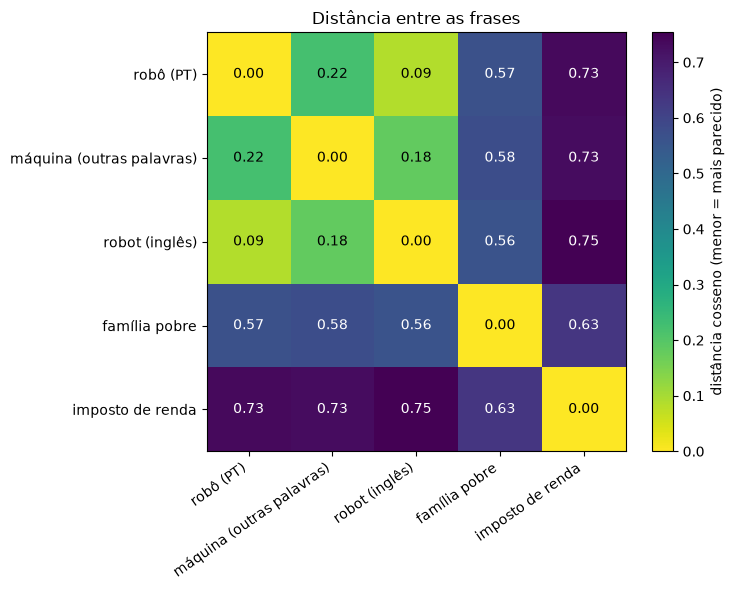

In [5]:
frases = {
    "robô (PT)": "Um robô solitário limpa a Terra abandonada e se apaixona.",
    "máquina (outras palavras)": "Uma máquina sozinha recolhe o lixo de um planeta vazio e encontra o amor.",
    "robot (inglês)": "A lonely robot cleans an abandoned Earth and falls in love.",
    "família pobre": "Uma família pobre se infiltra na casa de uma família rica.",
    "imposto de renda": "Como declarar o imposto de renda?",
}

# Uma linha por frase: matriz 5 x 1024.
E = np.array([gerar_embedding(frase) for frase in frases.values()])

# Os vetores têm norma 1, então distância cosseno = 1 − produto escalar.
# E @ E.T calcula o produto escalar de todos os pares de uma vez.
distancias = 1 - E @ E.T

rotulos = list(frases)
limite_cor = distancias.max() / 2

fig, ax = plt.subplots(figsize=(7.5, 6))
imagem = ax.imshow(distancias, cmap="viridis_r", vmin=0, vmax=distancias.max())
ax.set_xticks(range(len(rotulos)), rotulos, rotation=35, ha="right")
ax.set_yticks(range(len(rotulos)), rotulos)
for i, j in np.ndindex(distancias.shape):
    cor = "black" if distancias[i, j] < limite_cor else "white"
    ax.text(j, i, fmt(distancias[i, j], 2), ha="center", va="center", color=cor)
fig.colorbar(imagem, label="distância cosseno (menor = mais parecido)")
ax.set_title("Distância entre as frases")
plt.tight_layout()
plt.show()

## 3. O espaço vetorial em 2D

**Roteiro:** Parte 2.

Não dá para desenhar 1024 dimensões. A PCA acha as 2 direções em que os 400 filmes mais variam e projeta cada filme nelas, como a sombra de um objeto numa parede.

- Gêneros parecidos tendem a formar regiões: animação de um lado, ficção científica e guerra de outro.
- **Ressalva obrigatória:** as 2 direções guardam uma parte pequena da variação (o percentual aparece ao executar). Perto no gráfico não garante perto de verdade. A busca usa as 1024 dimensões.
- O gênero não foi usado para posicionar nada: ele só pinta os pontos depois. A posição vem só do texto.

As 2 direções guardam 6.3% da variação das 1024 dimensões.


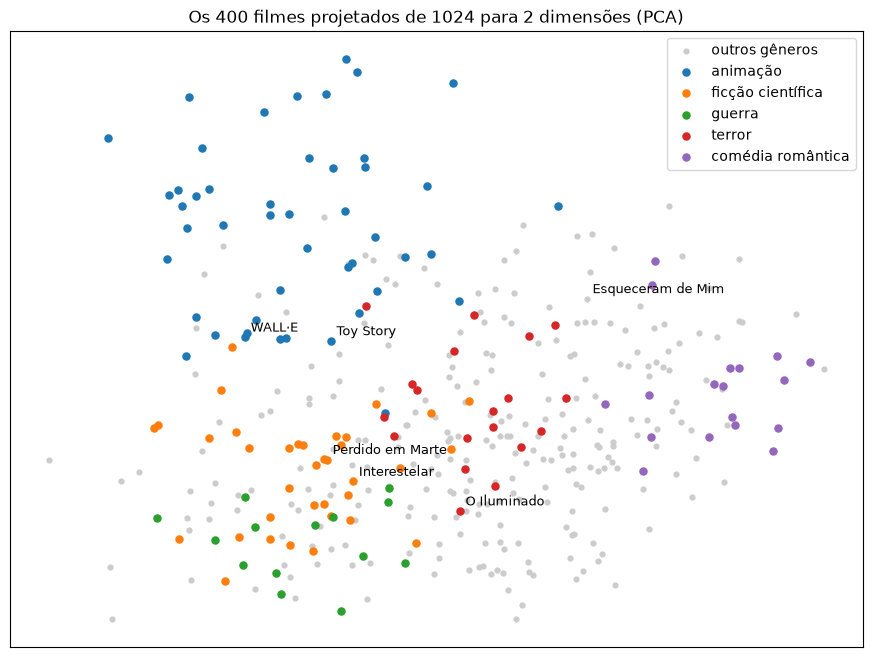

In [6]:
linhas = consultar("SELECT titulo, texto, embedding FROM kb_docs ORDER BY id")


def primeiro_genero(texto: str) -> str:
    """Lê a linha 'Gênero: a, b' do texto gravado e devolve o primeiro gênero."""
    linha = next(l for l in texto.splitlines() if l.startswith("Gênero:"))
    return linha.removeprefix("Gênero:").split(",")[0].strip()


titulos = [titulo for titulo, _, _ in linhas]
generos = np.array([primeiro_genero(texto) for _, texto, _ in linhas])
X = np.array([vetor for _, _, vetor in linhas], dtype=np.float64)  # 400 x 1024

# PCA: centraliza os dados e usa a SVD para achar as direções de maior variação.
centrado = X - X.mean(axis=0)
_, valores_singulares, direcoes = np.linalg.svd(centrado, full_matrices=False)
pontos = centrado @ direcoes[:2].T  # 400 x 2
variancia = valores_singulares**2 / np.sum(valores_singulares**2)
print(f"As 2 direções guardam {variancia[:2].sum():.1%} da variação das {X.shape[1]} dimensões.")

destaque = ["animação", "ficção científica", "guerra", "terror", "comédia romântica"]
nomeados = ["Interestelar", "Perdido em Marte", "WALL·E", "Toy Story", "O Iluminado", "Esqueceram de Mim"]

fig, ax = plt.subplots(figsize=(11, 8))
outros = ~np.isin(generos, destaque)
ax.scatter(*pontos[outros].T, s=12, color="#cccccc", label="outros gêneros")
for genero in destaque:
    ax.scatter(*pontos[generos == genero].T, s=26, label=genero)
for titulo in nomeados:
    ax.annotate(titulo, pontos[titulos.index(titulo)], fontsize=9,
                xytext=(4, 4), textcoords="offset points")
ax.set_title(f"Os {len(titulos)} filmes projetados de {X.shape[1]} para 2 dimensões (PCA)")
ax.set_xticks([])  # os eixos da projeção não têm unidade
ax.set_yticks([])
ax.legend()
plt.show()

## 4. O cosseno olha a direção, não o tamanho

**Roteiro:** Parte 5. Substitui o antigo `02-exemplos.sql`: vetores pequenos, sem tabela, direto no Oracle com `TO_VECTOR`.

- Distância cosseno = 1 − cosseno do ângulo: **0** na mesma direção, **1** a 90°, **2** em direções opostas.
- `[1, 2, 3]` e `[2, 4, 6]` têm distância cosseno 0: o tamanho dobrou, a direção é a mesma. A euclidiana, que mede o tamanho do caminho entre as pontas, não dá 0.
- **Menor é mais parecido.** Distância não é similaridade.

In [7]:
pares = [
    ("[1, 2, 3]", "[2, 4, 6]", "mesma direção, o dobro do tamanho"),
    ("[1, 2, 3]", "[1, 2, 3]", "iguais"),
    ("[1, 0]", "[0, 1]", "perpendiculares (90°)"),
    ("[1, 0]", "[-1, 0]", "opostos (180°)"),
]

print(f"{'a':>10} {'b':>10} {'cosseno':>8} {'euclidiana':>11}")
for a, b, descricao in pares:
    [(cosseno, euclidiana)] = consultar(
        """
        SELECT VECTOR_DISTANCE(TO_VECTOR(:a), TO_VECTOR(:b), COSINE),
               VECTOR_DISTANCE(TO_VECTOR(:a), TO_VECTOR(:b), EUCLIDEAN)
        FROM   dual
        """,
        a=a,
        b=b,
    )
    print(f"{a:>10} {b:>10} {fmt(cosseno):>8} {fmt(euclidiana):>11}   {descricao}")

         a          b  cosseno  euclidiana
 [1, 2, 3]  [2, 4, 6]   0.0000      3.7417   mesma direção, o dobro do tamanho
 [1, 2, 3]  [1, 2, 3]   0.0000      0.0000   iguais
    [1, 0]     [0, 1]   1.0000      1.4142   perpendiculares (90°)
    [1, 0]    [-1, 0]   2.0000      2.0000   opostos (180°)


## 5. A conta à mão bate com o Oracle

**Roteiro:** Parte 5.

A mesma distância calculada de três jeitos para um par perto (Interestelar e Perdido em Marte) e um par longe (Interestelar e o filme mais distante dele na base).

- **À mão:** 1 − (a · b) / (‖a‖ · ‖b‖).
- **Atalho:** como a norma é 1, basta 1 − a · b.
- **Oracle:** `VECTOR_DISTANCE(..., COSINE)`. As diferenças, se aparecerem, ficam na sexta ou sétima casa, por arredondamento do FLOAT32.

Resposta pronta para a banca, na última linha de cada par: com vetores de norma 1, euclidiana² / 2 = distância cosseno. As duas métricas dão o mesmo ranking. A escolha do cosseno segue o padrão do `VECTOR_DISTANCE` e o uso usual em embeddings de texto, sem prejuízo para a ordem.

In [8]:
def vetor_do_filme(titulo: str) -> np.ndarray:
    [(vetor,)] = consultar("SELECT embedding FROM kb_docs WHERE titulo = :titulo", titulo=titulo)
    return np.array(vetor, dtype=np.float64)


pares = [
    ("Interestelar", "Perdido em Marte"),
    ("Interestelar", "Branca de Neve e os Sete Anões"),
]

for titulo_a, titulo_b in pares:
    a, b = vetor_do_filme(titulo_a), vetor_do_filme(titulo_b)
    cosseno_mao = 1 - (a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))
    [(cosseno_oracle, euclidiana_oracle)] = consultar(
        """
        SELECT VECTOR_DISTANCE(a.embedding, b.embedding, COSINE),
               VECTOR_DISTANCE(a.embedding, b.embedding, EUCLIDEAN)
        FROM   kb_docs a CROSS JOIN kb_docs b
        WHERE  a.titulo = :titulo_a AND b.titulo = :titulo_b
        """,
        titulo_a=titulo_a,
        titulo_b=titulo_b,
    )
    print(f"{titulo_a} x {titulo_b}")
    print(f"  à mão (numpy)           {cosseno_mao:.6f}")
    print(f"  1 − produto escalar     {1 - a @ b:.6f}")
    print(f"  Oracle, COSINE          {cosseno_oracle:.6f}")
    print(f"  Oracle, EUCLIDEAN² / 2  {euclidiana_oracle**2 / 2:.6f}")
    print()

Interestelar x Perdido em Marte
  à mão (numpy)           0.314852
  1 − produto escalar     0.314853
  Oracle, COSINE          0.314852
  Oracle, EUCLIDEAN² / 2  0.314852

Interestelar x Branca de Neve e os Sete Anões
  à mão (numpy)           0.579294
  1 − produto escalar     0.579294
  Oracle, COSINE          0.579294
  Oracle, EUCLIDEAN² / 2  0.579294



## 6. O top-k sempre devolve k

**Roteiro:** Partes 5 e 6.

As 10 perguntas do `perguntas.json`, pela mesma função da API (`buscar_filmes`), com a distância do 1º lugar de cada uma.

- A busca nunca responde "não sei": toda pergunta recebe 3 filmes, inclusive a do imposto de renda.
- A pista é a distância: a pergunta fora da base (em vermelho) fica acima da média das outras.
- Um limite de distância para dizer "nada parecido" seria um próximo passo, calibrado com mais perguntas. Com 10, ainda é cedo.

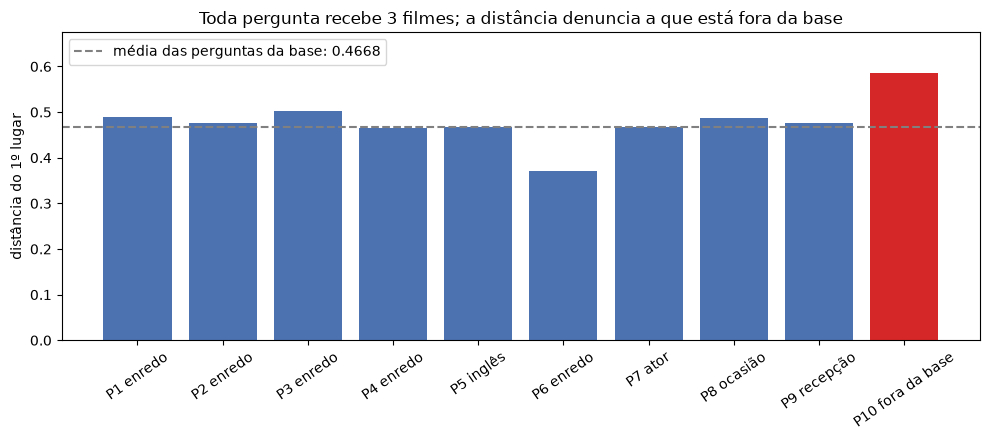

P1 enredo            WALL·E                                        0.4900
P2 enredo            Apertem os Cintos… o Piloto Sumiu!            0.4767
P3 enredo            Matrix                                        0.5014
P4 enredo            Feitiço do Tempo                              0.4645
P5 inglês            Parasita                                      0.4676
P6 enredo            Ex Machina: Instinto Artificial               0.3703
P7 ator              Central do Brasil                             0.4682
P8 ocasião           Gremlins                                      0.4872
P9 recepção          As Patricinhas de Beverly Hills               0.4754
P10 fora da base     Jerry Maguire: A Grande Virada                0.5868


In [9]:
perguntas = ler_json("data/perguntas.json")

resultados = [buscar_filmes(caso["pergunta"], limite=3) for caso in perguntas]
top1 = np.array([resultado[0]["distancia"] for resultado in resultados])
fora = np.array([not caso["esperados"] for caso in perguntas])
media_base = top1[~fora].mean()

rotulos = [f"P{i} {caso['categoria']}" for i, caso in enumerate(perguntas, start=1)]
cores = ["#d62728" if fora_da_base else "#4c72b0" for fora_da_base in fora]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(rotulos, top1, color=cores)
ax.axhline(media_base, linestyle="--", color="gray",
           label=f"média das perguntas da base: {fmt(media_base)}")
ax.set_ylabel("distância do 1º lugar")
ax.set_ylim(0, top1.max() * 1.15)
ax.tick_params(axis="x", rotation=35)
ax.legend(loc="upper left")
ax.set_title("Toda pergunta recebe 3 filmes; a distância denuncia a que está fora da base")
plt.tight_layout()
plt.show()

for rotulo, resultado in zip(rotulos, resultados):
    primeiro = resultado[0]
    print(f"{rotulo:<20} {primeiro['titulo']:<45} {fmt(primeiro['distancia'])}")

## 7. (Opcional) A troca silenciosa de modelo

**Roteiro:** Parte 2 (regra do mesmo modelo nos dois lados) ou resposta de banca.

Antes, rode `ollama pull mxbai-embed-large` (cerca de 670 MB). Esse modelo também gera 1024 números.

- A mesma pergunta, vetorizada pelo bge-m3 e pelo mxbai-embed-large, é buscada contra os vetores do bge-m3 gravados na tabela.
- Nada dá erro: a dimensão bate, o Oracle calcula e devolve 3 filmes. O resultado errado tem cara de resultado.
- **Prevenção, não só detecção:** o `vetores.json` guarda o nome do modelo, e o `python -m app.vetores importar` recusa o arquivo se o modelo configurado for outro.

In [10]:
OUTRO_MODELO = "mxbai-embed-large"  # também gera 1024 números
pergunta = "Filme sobre um homem que se apaixona por uma inteligência artificial"


def top3(vetor: list[float]) -> list[tuple]:
    """A mesma consulta da API, recebendo um vetor pronto."""
    return consultar(
        """
        SELECT titulo, VECTOR_DISTANCE(embedding, :vetor, COSINE) AS distancia
        FROM   kb_docs
        ORDER  BY distancia
        FETCH FIRST 3 ROWS ONLY
        """,
        vetor=array.array("f", vetor),
    )


try:
    resposta = requests.post(URL, json={"model": OUTRO_MODELO, "input": pergunta}, timeout=120)
    resposta.raise_for_status()
except requests.RequestException as erro:
    print(f"Não deu para usar o {OUTRO_MODELO}: {erro}")
    print(f"Baixe o modelo antes: ollama pull {OUTRO_MODELO}")
else:
    vetor_errado = resposta.json()["embeddings"][0]
    print(f"{OUTRO_MODELO}: {len(vetor_errado)} números, a mesma dimensão da coluna.\n")
    for modelo, vetor in [(MODELO, gerar_embedding(pergunta)), (OUTRO_MODELO, vetor_errado)]:
        print(f"Pergunta vetorizada com {modelo}:")
        for titulo, distancia in top3(vetor):
            print(f"  {titulo:<45} {fmt(distancia)}")
        print()

Não deu para usar o mxbai-embed-large: 404 Client Error: Not Found for url: http://localhost:11434/api/embed
Baixe o modelo antes: ollama pull mxbai-embed-large


## Encerramento

In [11]:
conexao.close()